# 2014 — Attention (Bahdanau)

**Paper:** Dzmitry Bahdanau, Kyunghyun Cho & Yoshua Bengio, *"Neural Machine Translation by Jointly Learning to Align and Translate"* (2014). Luong et al. (2015) proposed the multiplicative variant.

Instead of one fixed vector, the decoder **looks back at all encoder states** at every step and takes a weighted average:

$$
e_{t,j} = v^\top \tanh(W_s s_{t-1} + W_h h_j), \qquad \alpha_{t,j} = \operatorname{softmax}_j(e_{t,j}), \qquad c_t = \sum_j \alpha_{t,j} h_j
$$

The weights $\alpha$ form a soft, learned **alignment**, which can be plotted. This idea, stripped of the RNN, becomes the Transformer (2017).

Task: translate human-written dates into ISO format, e.g. `"tuesday, march 3 1998"` → `"1998-03-03"`.

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)
import datetime

PyTorch 2.15.0 | device: mps


In [2]:
rng = random.Random(0)
formats = ["%A, %B %d %Y", "%d %B %Y", "%b %d, %Y", "%d.%m.%Y", "%B %d %Y", "%a %d %b %Y", "%m/%d/%Y"]
def make_example():
    d = datetime.date(1950, 1, 1) + datetime.timedelta(days=rng.randrange(0, 365 * 80))
    src = d.strftime(rng.choice(formats)).lower()
    if rng.random() < 0.5: src = src.replace(" 0", " ")        # sometimes drop leading zeros
    return src, d.isoformat()

pairs = [make_example() for _ in range(30000)]
src_chars = sorted(set("".join(s for s, _ in pairs))); tgt_chars = sorted(set("".join(t for _, t in pairs)))
PAD, SOS = 0, 1
sv = {c: i + 1 for i, c in enumerate(src_chars)}; tv = {c: i + 2 for i, c in enumerate(tgt_chars)}
itos_t = {i: c for c, i in tv.items()}
Ls = max(len(s) for s, _ in pairs)
def encode(batch_pairs):
    X = torch.tensor([[sv[c] for c in s] + [PAD] * (Ls - len(s)) for s, _ in batch_pairs])
    Y = torch.tensor([[tv[c] for c in t] for _, t in batch_pairs])
    return X.to(device), Y.to(device)
for s, t in pairs[:4]: print(f"{s:30s} -> {t}")

04.10.2025                     -> 2025-10-04
friday, september 25 1987      -> 1987-09-25
14.11.1995                     -> 1995-11-14
04/26/2020                     -> 2020-04-26


In [3]:
class AttnSeq2Seq(nn.Module):
    def __init__(self, Vs, Vt, d=128):
        super().__init__()
        self.semb = nn.Embedding(Vs, d, padding_idx=PAD); self.temb = nn.Embedding(Vt, d)
        self.encoder = nn.GRU(d, d, batch_first=True, bidirectional=True)
        self.W_h = nn.Linear(2 * d, d, bias=False); self.W_s = nn.Linear(d, d); self.v = nn.Linear(d, 1, bias=False)
        self.cell = nn.GRUCell(d + 2 * d, d)
        self.out = nn.Linear(d + 2 * d, Vt)
        self.d = d

    def forward(self, src, tgt):
        H, _ = self.encoder(self.semb(src))                  # (B, S, 2d): one state per input char
        mask = src != PAD
        keys = self.W_h(H)
        s = torch.zeros(len(src), self.d, device=src.device)
        prev = torch.full((len(src),), SOS, device=src.device)
        logits, alphas = [], []
        for t in range(tgt.shape[1]):
            e = self.v(torch.tanh(keys + self.W_s(s).unsqueeze(1))).squeeze(-1)   # additive attention score
            e = e.masked_fill(~mask, -1e9)
            a = F.softmax(e, -1)                                                  # alignment weights
            c = (a.unsqueeze(-1) * H).sum(1)                                      # context vector
            s = self.cell(torch.cat([self.temb(prev), c], -1), s)
            logit = self.out(torch.cat([s, c], -1))
            logits.append(logit); alphas.append(a)
            prev = tgt[:, t] if self.training else logit.argmax(-1)               # teacher forcing / greedy
        return torch.stack(logits, 1), torch.stack(alphas, 1)

model = AttnSeq2Seq(len(sv) + 1, len(tv) + 2).to(device)
opt = torch.optim.Adam(model.parameters(), lr=2e-3)
train, test = pairs[:28000], pairs[28000:]
for step in range(1501):
    model.train()
    X, Y = encode(rng.sample(train, 128))
    logits, _ = model(X, Y)
    loss = F.cross_entropy(logits.reshape(-1, logits.shape[-1]), Y.reshape(-1))
    opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
    if step % 300 == 0:
        model.eval()
        with torch.no_grad():
            Xt, Yt = encode(test); pred = model(Xt, Yt)[0].argmax(-1)
        print(f"step {step:4d} loss {loss.item():.3f} | exact-match on held-out dates {(pred == Yt).all(1).float().mean():.3f}")

step    0 loss 2.607 | exact-match on held-out dates 0.000


step  300 loss 0.000 | exact-match on held-out dates 1.000


step  600 loss 0.000 | exact-match on held-out dates 1.000


step  900 loss 0.000 | exact-match on held-out dates 1.000


step 1200 loss 0.000 | exact-match on held-out dates 1.000


step 1500 loss 0.000 | exact-match on held-out dates 1.000


## Visualising the alignment
Each output character attends to the input characters it comes from. The month digits attend to the month name, and the year digits attend to the year.

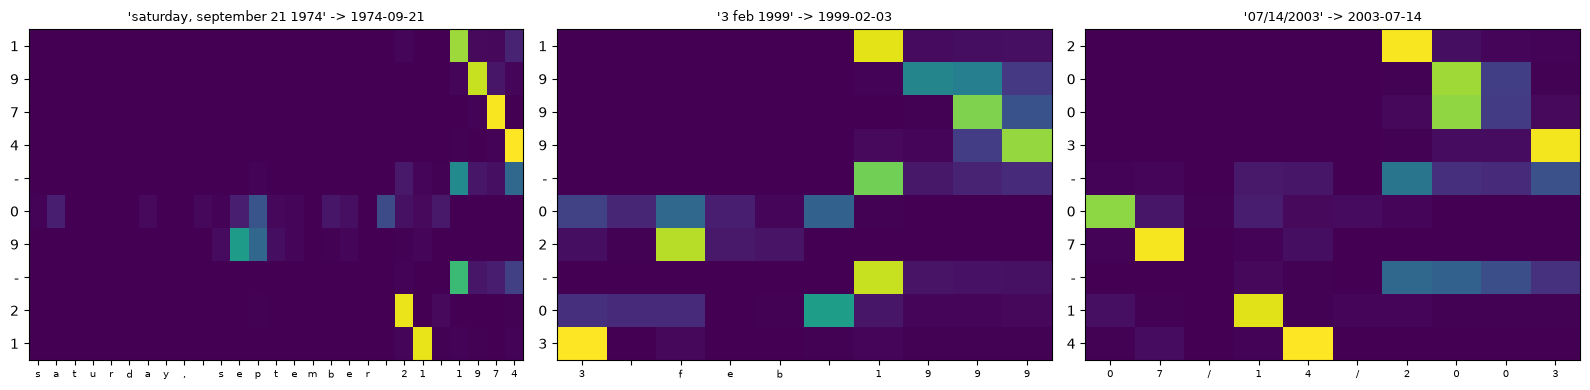

In [4]:
model.eval()
examples = ["saturday, september 21 1974", "3 feb 1999", "07/14/2003"]
fig, axes = plt.subplots(1, len(examples), figsize=(16, 4))
for ax, s in zip(axes, examples):
    X, Y = encode([(s, "0000-00-00")])
    with torch.no_grad(): logits, A = model(X, Y)
    out = "".join(itos_t[i] for i in logits.argmax(-1)[0].tolist())
    ax.imshow(A[0, :, :len(s)].cpu(), cmap="viridis", aspect="auto")
    ax.set_xticks(range(len(s))); ax.set_xticklabels(list(s), fontsize=7)
    ax.set_yticks(range(len(out))); ax.set_yticklabels(list(out))
    ax.set_title(f"'{s}' -> {out}", fontsize=9)
plt.tight_layout(); plt.show()